# Idea 3 - The GPT Lag

**The claim (Second Machine Age, ch. 7; Machines, Platforms, Crowds, ch. 1).**
General purpose technologies do not pay off when they are invented. They pay
off decades later, once organisations have been rebuilt around them. The book's
evidence is electrification: Devine found the group-drive versus unit-drive
question still being argued twenty-five years on, and David and Wright put the
delay down to "the need for organisational and above all for conceptual
changes in the ways tasks and products are defined and structured."

**The problem with testing it.** The lag is usually asserted with two curves
placed side by side. Two curves cannot establish a lag; they can only illustrate
one that is assumed. So this notebook does three things, in increasing order of
how much they are worth:

1. **The investment wave.** When did American firms actually buy the technology?
2. **The era comparison.** The book's Figure 7.2, rebuilt from what the public
   APIs hold, with an explicit statement of what could not be obtained.
3. **The lag, estimated.** Correlate information-technology capital deepening
   at year t with productivity growth at year t+k, for k from 0 to 25, and see
   where the correlation peaks. Then run the same test on a placebo capital
   series, because a lag that shows up for every kind of investment is not
   evidence about general purpose technologies.

The placebo is the part that makes this worth doing. Without it, a peak at
k = 15 is a number with no way of being wrong.

**Data.** BEA NIPA Tables 5.3.3 and 5.3.5; FRED for productivity and for
whatever pre-war series can be found. Uses the BEA and FRED keys only.

In [1]:
import sys, pathlib, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

_here = pathlib.Path.cwd()
for _cand in [_here, *_here.parents]:
    if (_cand / "common" / "stacklib.py").exists():
        sys.path.insert(0, str(_cand / "common"))
        break
import stacklib as sl
importlib.reload(sl)

warnings.filterwarnings("ignore", category=FutureWarning)
print("stacklib version:", sl.__version__)

DIRS = sl.dirs_for("03_the_gpt_lag")
KEYS = sl.load_keys()
sl.apply_theme()

BEA = sl.require(KEYS, "BEA")
FRED = sl.require(KEYS, "FRED")
MAX_LAG = 25

stacklib version: 0.3.0
Keys loaded from .env: BEA, BLS, CENSUS, FRED


## 1. The investment wave

Before asking when the payoff arrived, establish when the spending happened.
Information processing equipment plus software, as a share of private fixed
investment, dates the adoption wave.

BEA T50305: 2403 rows, 31 lines, 1947-2025
BEA T50303: 2403 rows, 31 lines, 1947-2025
line numbering verified

match All fixed investment     -> line   1  Private fixed investment
match Structures               -> line   3  Structures
match Equipment                -> line   9  Equipment
match Info processing equip.   -> line  10  Information processing equipment
match Computers                -> line  11  Computers and peripheral equipment
match Intellectual property    -> line  16  Intellectual property products
match Software                 -> line  17  Software
match All fixed investment     -> line   1  Private fixed investment
match Structures               -> line   3  Structures
match Equipment                -> line   9  Equipment
match Info processing equip.   -> line  10  Information processing equipment
match Computers                -> line  11  Computers and peripheral equipment
match Intellectual property    -> line  16  Intellectual property products
match Software    

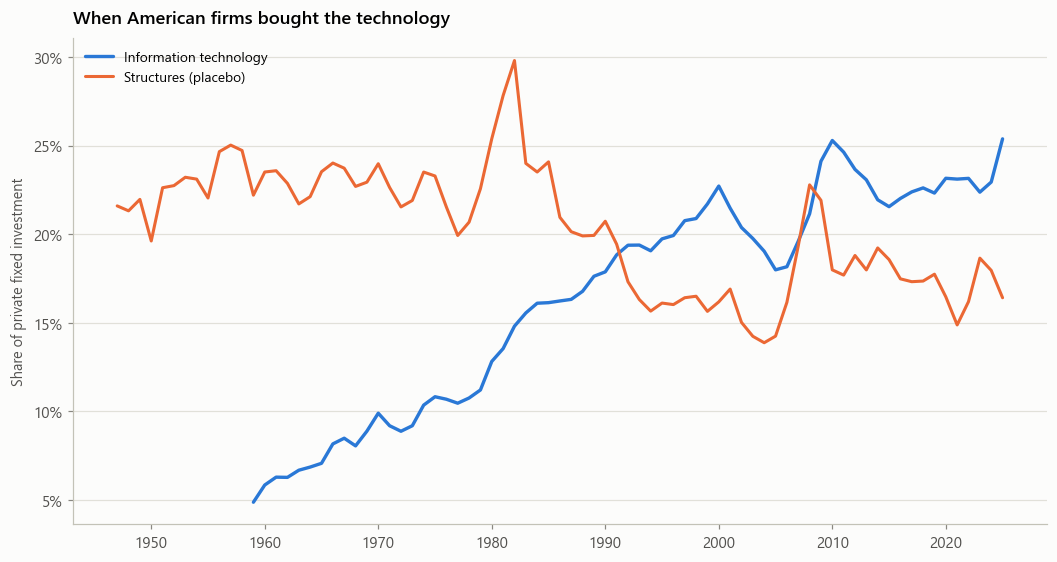

IT share peaked in 2025 at 25.4%


In [2]:
inv_cur = sl.bea_nipa_table("T50305", BEA, frequency="A", cache_dir=DIRS["data"])
inv_qty = sl.bea_nipa_table("T50303", BEA, frequency="A", cache_dir=DIRS["data"])

LINES = {"All fixed investment": 1, "Structures": 3, "Equipment": 9,
         "Info processing equip.": 10, "Computers": 11,
         "Intellectual property": 16, "Software": 17}

EXPECT = {1: "private fixed investment", 3: "structures", 9: "equipment",
          10: "information processing", 11: "computers", 16: "intellectual property",
          17: "software"}
descs = dict(zip(inv_cur["line"], inv_cur["description"].astype(str).str.strip().str.lower()))
bad = {ln: descs.get(ln) for ln, w in EXPECT.items() if w not in (descs.get(ln) or "")}
if bad:
    raise AssertionError("BEA line numbering has moved. Mismatches: %s" % bad)
print("line numbering verified\n")

CUR = sl.pick_lines(inv_cur, LINES)
QTY = sl.pick_lines(inv_qty, LINES)

it_share = ((CUR["Info processing equip."] + CUR["Software"])
            / CUR["All fixed investment"] * 100).dropna()
structures_share = (CUR["Structures"] / CUR["All fixed investment"] * 100).dropna()

fig, ax = plt.subplots(figsize=(9.5, 5.0))
ax.plot(it_share.index, it_share.values, color=sl.PALETTE[0], lw=2.2,
        label="Information technology")
ax.plot(structures_share.index, structures_share.values, color=sl.PALETTE[1], lw=2.0,
        label="Structures (placebo)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%.0f%%" % v))
ax.set_ylabel("Share of private fixed investment")
ax.set_title("When American firms bought the technology")
ax.legend(loc="upper left")
sl.save_fig(fig, "fig1_it_investment_wave", DIRS)
plt.show()
print("IT share peaked in %d at %.1f%%" % (it_share.idxmax(), it_share.max()))

## 2. The era comparison, and what the data will not give us

The book's Figure 7.2 plots labour productivity across 1890-1940 against
1970-2020. BLS major-sector productivity begins in 1947 and BEA's accounts
begin in 1929, so the electrification half of that chart cannot be rebuilt from
these sources at all. The cell below searches FRED for the longest series it
holds, prints the candidates, and assembles the best available substitute.
Read the printout before trusting the figure that follows it.

In [3]:
for term in ["industrial production historical",
             "manufacturing average weekly hours NBER",
             "manufacturing employment NBER historical",
             "gross national product historical united states"]:
    print("=== %s ===" % term)
    df = sl.fred_search(term, FRED, limit=6)
    print(df.to_string(index=False) if len(df) else "(nothing)")
    print()

=== industrial production historical ===
               id                                                                                                                                    title freq               units from   to  popularity
           OPHNFB                                                            Nonfarm Business Sector: Labor Productivity (Output per Hour) for All Workers    Q      Index 2017=100 1947 2026          69
           ULCNFB                                                                                Nonfarm Business Sector: Unit Labor Costs for All Workers    Q      Index 2017=100 1947 2026          46
         COMPRNFB                                                                        Nonfarm Business Sector: Real Hourly Compensation for All Workers    Q      Index 2017=100 1947 2026          44
          COMPNFB                                                                             Nonfarm Business Sector: Hourly Compensation for All Work

In [4]:
def annual(s):
    a = s.groupby(s.index.year).mean()
    a.index = a.index.astype(int)
    return a

tfp_id, tfp_raw = sl.fred_first_available(
    ["RTFPNAUSA632NRUG", "MFPNFBS", "OPHNFB"], FRED, cache_dir=DIRS["data"])
TFP = annual(tfp_raw)

# Era 1: the Federal Reserve industrial production index reaches back to 1919,
# which covers the second half of electrification, the part where the payoff is
# supposed to appear. It measures output, not productivity. Say so on the chart.
era1_id, era1_series, era1_kind = None, None, None
try:
    era1_id, era1_raw = sl.fred_first_available(["INDPRO"], FRED, cache_dir=DIRS["data"])
    era1_series = annual(era1_raw)
    era1_kind = "industrial output"
except Exception as e:
    print("Era 1 unavailable from FRED (%s). The comparison figure will be skipped." % e)

# Era 2: postwar labour productivity, the same concept the book plots.
era2_id, era2_raw = sl.fred_first_available(["OPHNFB", "OPHPBS"], FRED, cache_dir=DIRS["data"])
era2_series = annual(era2_raw)
print("\nera 1: %s (%s)   era 2: %s (output per hour)   TFP: %s"
      % (era1_id, era1_kind, era2_id, tfp_id))

FRED RTFPNAUSA632NRUG: 70 obs, 1954-01-01-2023-01-01
FRED INDPRO: 1291 obs, 1919-01-01-2026-07-01
FRED OPHNFB: 318 obs, 1947-01-01-2026-04-01

era 1: INDPRO (industrial output)   era 2: OPHNFB (output per hour)   TFP: RTFPNAUSA632NRUG


### Figure 2 - Two eras on one clock

Both eras are indexed to 100 at their own starting year and drawn against
years elapsed rather than calendar years, so one y axis serves both. This is a
cleaner construction than the book's twin time axes, and it makes the shapes
directly comparable. The two series measure different things, which the caption
and the write-up both state.

saved -> C:\Users\91838\Downloads\Stack_Article\03_the_gpt_lag\figures\fig2_two_eras.png


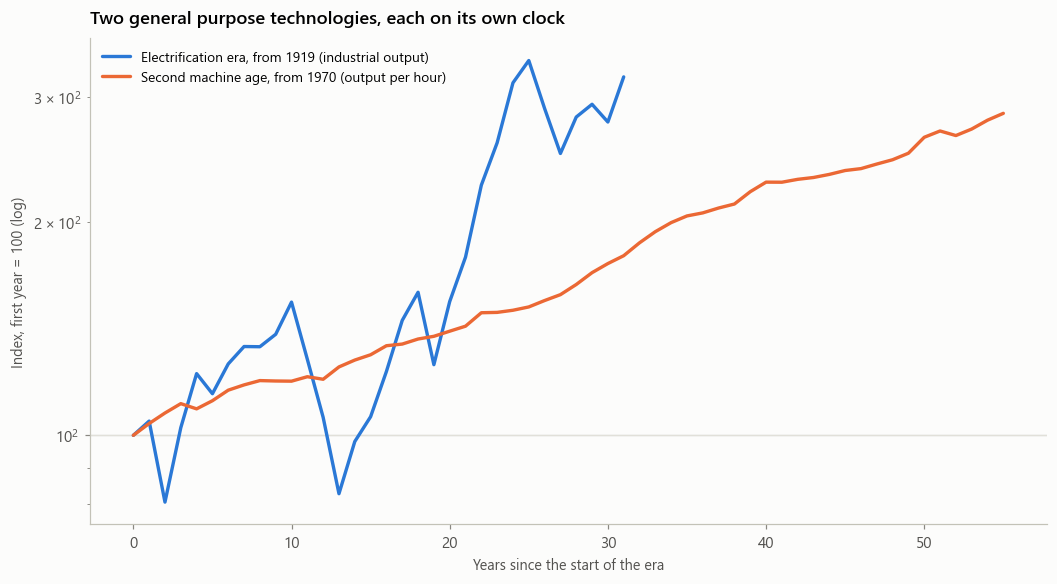

In [5]:
if era1_series is not None:
    e1 = era1_series[(era1_series.index >= 1919) & (era1_series.index <= 1950)]
    e2 = era2_series[(era2_series.index >= 1970) & (era2_series.index <= 2025)]
    e1i = e1 / e1.iloc[0] * 100
    e2i = e2 / e2.iloc[0] * 100

    fig, ax = plt.subplots(figsize=(9.5, 5.2))
    ax.plot(np.arange(len(e1i)), e1i.values, color=sl.PALETTE[0], lw=2.2,
            label="Electrification era, from %d (%s)" % (e1.index[0], era1_kind))
    ax.plot(np.arange(len(e2i)), e2i.values, color=sl.PALETTE[1], lw=2.2,
            label="Second machine age, from %d (output per hour)" % e2.index[0])
    ax.set_yscale("log")
    ax.axhline(100, color=sl.INK["axis"], lw=0.8, zorder=0)
    ax.set_xlabel("Years since the start of the era")
    ax.set_ylabel("Index, first year = 100 (log)")
    ax.set_title("Two general purpose technologies, each on its own clock")
    ax.legend(loc="upper left")
    sl.save_fig(fig, "fig2_two_eras", DIRS)
    plt.show()
else:
    print("Skipped: no pre-war series available.")

## 3. Estimating the lag

The test. For each lag k from 0 to 25, correlate the information-technology
investment share in year t with productivity growth in year t+k. Both series
trend, and correlating two trending series manufactures significance, so the
same test runs on first differences, which removes the shared trend. The
structures share gets the identical treatment as a placebo.

A result worth reporting looks like a clear peak for IT at a plausible k, with
no matching peak for structures. Anything else is noise wearing a lag's clothes.

saved -> C:\Users\91838\Downloads\Stack_Article\03_the_gpt_lag\figures\fig3_lag_profile.png


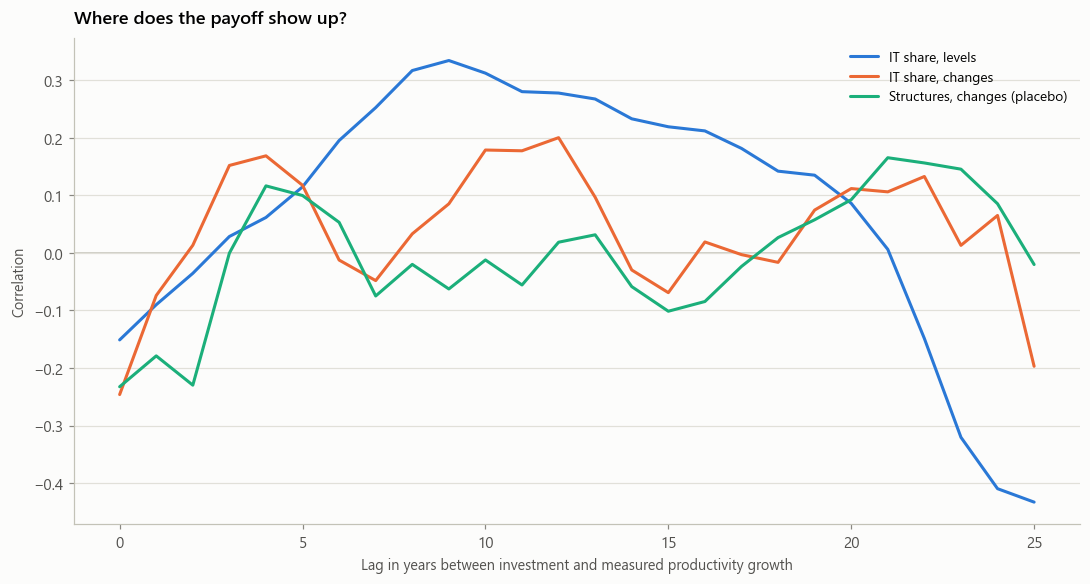

                                lag   corr  corr_at_zero
IT share, levels                9.0  0.334        -0.151
IT share, changes              12.0  0.200        -0.246
Structures, changes (placebo)  21.0  0.165        -0.232


In [6]:
tfp_growth = (TFP.pct_change() * 100).dropna()
tfp_smooth = tfp_growth.rolling(5, center=True).mean().dropna()

def lag_profile(driver, response, max_lag=MAX_LAG, differences=False):
    d = driver.diff().dropna() if differences else driver.dropna()
    out = {}
    for k in range(max_lag + 1):
        shifted = d.copy()
        shifted.index = shifted.index + k
        common = shifted.index.intersection(response.index)
        if len(common) < 20:
            continue
        out[k] = float(np.corrcoef(shifted.loc[common], response.loc[common])[0, 1])
    return pd.Series(out)

profiles = {
    "IT share, levels": lag_profile(it_share, tfp_smooth),
    "IT share, changes": lag_profile(it_share, tfp_smooth, differences=True),
    "Structures, changes (placebo)": lag_profile(structures_share, tfp_smooth, differences=True),
}

fig, ax = plt.subplots(figsize=(9.8, 5.2))
for (name, prof), color in zip(profiles.items(), sl.PALETTE[:3]):
    ax.plot(prof.index, prof.values, color=color, lw=2.0, label=name)
ax.axhline(0, color=sl.INK["axis"], lw=1.0, zorder=0)
ax.set_xlabel("Lag in years between investment and measured productivity growth")
ax.set_ylabel("Correlation")
ax.set_title("Where does the payoff show up?")
ax.legend(loc="best")
sl.save_fig(fig, "fig3_lag_profile", DIRS)
plt.show()

peaks = {name: {"lag": int(p.idxmax()), "corr": float(p.max()),
                "corr_at_zero": float(p.get(0, np.nan))}
         for name, p in profiles.items() if len(p)}
print(pd.DataFrame(peaks).T.round(3).to_string())

### Figure 4 - The peak lag, drawn as a scatter

A correlation is a summary. This shows the underlying points for the lag the
differenced IT series prefers, so the relationship can be inspected rather
than taken on faith.

saved -> C:\Users\91838\Downloads\Stack_Article\03_the_gpt_lag\figures\fig4_peak_lag_scatter.png


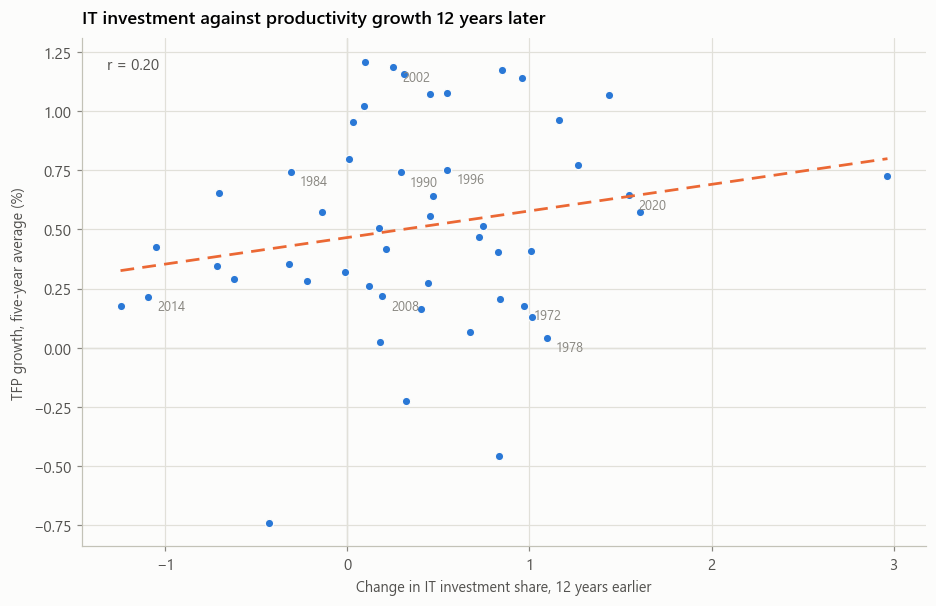

In [7]:
best_lag = peaks["IT share, changes"]["lag"]
d = it_share.diff().dropna()
d.index = d.index + best_lag
common = d.index.intersection(tfp_smooth.index)
x, y = d.loc[common].values, tfp_smooth.loc[common].values
slope, intercept = np.polyfit(x, y, 1)
r = float(np.corrcoef(x, y)[0, 1])

fig, ax = plt.subplots(figsize=(8.4, 5.4))
ax.scatter(x, y, s=30, color=sl.PALETTE[0], linewidths=0.8, edgecolors=sl.INK["surface"], zorder=2)
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, intercept + slope * xs, color=sl.PALETTE[1], lw=1.8, ls=(0, (5, 3)), zorder=3)
for yr in list(common)[::6]:
    i = list(common).index(yr)
    ax.annotate(str(yr), (x[i], y[i]), xytext=(6, -9), textcoords="offset points",
                fontsize=8.5, color=sl.INK["muted"])
ax.axhline(0, color=sl.INK["axis"], lw=0.8, zorder=0)
ax.axvline(0, color=sl.INK["axis"], lw=0.8, zorder=0)
ax.set_xlabel("Change in IT investment share, %d years earlier" % best_lag)
ax.set_ylabel("TFP growth, five-year average (%)")
ax.set_title("IT investment against productivity growth %d years later" % best_lag)
ax.annotate("r = %.2f" % r, xy=(0.03, 0.94), xycoords="axes fraction",
            color=sl.INK["secondary"], fontsize=10)
ax.grid(axis="x")
sl.save_fig(fig, "fig4_peak_lag_scatter", DIRS)
plt.show()

### Figure 5 - Productivity growth by era

The four windows economists usually mark out. Whatever the lag analysis says,
these are the facts it has to explain.

saved -> C:\Users\91838\Downloads\Stack_Article\03_the_gpt_lag\figures\fig5_growth_by_window.png


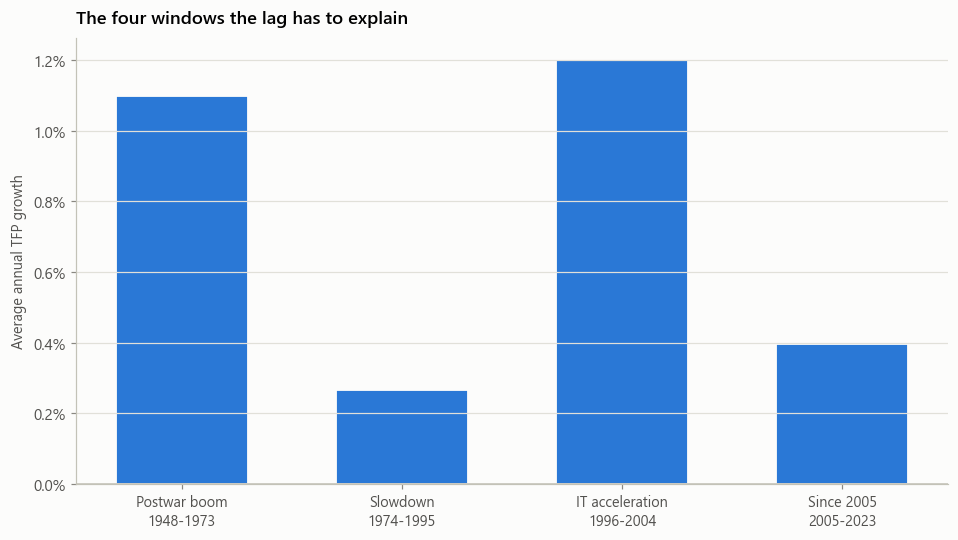

                     years  tfp_growth
window                                
Postwar boom     1948-1973       1.098
Slowdown         1974-1995       0.267
IT acceleration  1996-2004       1.202
Since 2005       2005-2023       0.395


In [8]:
WINDOWS = [(1948, 1973, "Postwar boom"), (1974, 1995, "Slowdown"),
           (1996, 2004, "IT acceleration"), (2005, int(tfp_growth.index.max()), "Since 2005")]
rows = [(lab, "%d-%d" % (a, b), float(tfp_growth[(tfp_growth.index >= a) & (tfp_growth.index <= b)].mean()))
        for a, b, lab in WINDOWS]
win = pd.DataFrame(rows, columns=["window", "years", "tfp_growth"]).set_index("window")

fig, ax = plt.subplots(figsize=(8.6, 4.8))
ax.bar(range(len(win)), win["tfp_growth"].values, width=0.6,
       color=sl.PALETTE[0], edgecolor=sl.INK["surface"], linewidth=1.2)
ax.set_xticks(range(len(win)))
ax.set_xticklabels(["%s\n%s" % (i, win.loc[i, "years"]) for i in win.index], fontsize=9.5)
ax.axhline(0, color=sl.INK["axis"], lw=1.0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%.1f%%" % v))
ax.set_ylabel("Average annual TFP growth")
ax.set_title("The four windows the lag has to explain")
sl.save_fig(fig, "fig5_growth_by_window", DIRS)
plt.show()
print(win.round(3).to_string())

## 4. Bank the numbers

In [9]:
payload = {
    "stacklib_version": sl.__version__,
    "tfp_series_used": tfp_id,
    "era1_series_used": era1_id, "era1_measure": era1_kind,
    "era2_series_used": era2_id,
    "it_share_peak_year": int(it_share.idxmax()),
    "it_share_peak_pct": float(it_share.max()),
    "it_share_latest_pct": float(it_share.iloc[-1]),
    "lag_peaks": peaks,
    "lag_profiles": {k: {int(i): round(float(v), 4) for i, v in p.items()} for k, p in profiles.items()},
    "best_lag_scatter": {"lag": int(best_lag), "r": r, "slope": float(slope), "n": int(len(x))},
    "tfp_growth_by_window": win["tfp_growth"].round(3).to_dict(),
    "max_lag_tested": MAX_LAG,
}
sl.write_findings(payload, DIRS)
pd.DataFrame(profiles).to_csv(pathlib.Path(DIRS["findings"]) / "lag_profiles.csv")
win.to_csv(pathlib.Path(DIRS["findings"]) / "tfp_growth_by_window.csv")
print("\nDone. Figures in figures/, numbers in findings/.")

findings -> C:\Users\91838\Downloads\Stack_Article\03_the_gpt_lag\findings\headline_numbers.json

Done. Figures in figures/, numbers in findings/.


## Caveats to carry into the prose

1. **A lag profile is not causal.** With roughly seventy annual observations and
   two heavily autocorrelated series, the peak lag has wide uncertainty and no
   identification. Report it as the lag the data prefer, not the lag that exists.
2. **The placebo decides how much to say.** If structures shows a similar peak,
   the IT result is about the business cycle rather than about general purpose
   technologies, and the section shrinks to one honest paragraph.
3. **Era 1 measures output, not productivity.** The Federal Reserve index starts
   in 1919 and counts production. Comparing it with output per hour compares two
   different quantities, so Figure 2 illustrates the shape of an adoption era
   and settles nothing on its own.
4. **Smoothing inflates correlations.** The five-year average on TFP growth
   removes noise and also removes independent observations.

**Send back:** the five PNGs, the FRED candidate printout from the search cell,
the peak table, the window table, and `findings/headline_numbers.json`. The
placebo row is the first thing I will look at.